In [3]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import scipy.io

DATA_DIR = Path("./dataset")
eeg_file = DATA_DIR / "EEG_01-26_MATLAB" / "VP001-EEG" / "cnt_nback.mat"
print(eeg_file)

dataset/EEG_01-26_MATLAB/VP001-EEG/cnt_nback.mat


In [4]:
mat = scipy.io.loadmat(eeg_file, squeeze_me=True, struct_as_record=False)
print(type(mat))
print(mat.keys())

<class 'dict'>
dict_keys(['__header__', '__version__', '__globals__', 'cnt_nback'])


In [5]:
data_keys = [k for k in mat.keys() if not k.startswith("__")]
print(data_keys)

cnt = mat[data_keys[0]]
print(type(cnt))
print(cnt._fieldnames)

['cnt_nback']
<class 'scipy.io.matlab._mio5_params.mat_struct'>
['clab', 'fs', 'title', 'file', 'x', 'T', 'yUnit']


In [6]:
print("Title:", cnt.title)
print("File:", cnt.file)
print("Sampling rate:", cnt.fs, "Hz")
print("Unit:", cnt.yUnit)
print("T:", cnt.T)
print("Number of channels:", len(cnt.clab))
print("Channel names:", cnt.clab)
print("x shape:", cnt.x.shape)

Title: nback
File: []
Sampling rate: 200 Hz
Unit: uV
T: 131614
Number of channels: 30
Channel names: ['Fp1' 'AFF5h' 'AFz' 'F1' 'FC5' 'FC1' 'T7' 'C3' 'Cz' 'CP5' 'CP1' 'P7' 'P3'
 'Pz' 'POz' 'O1' 'Fp2' 'AFF6h' 'F2' 'FC2' 'FC6' 'C4' 'T8' 'CP2' 'CP6' 'P4'
 'P8' 'O2' 'HEOG' 'VEOG']
x shape: (394930, 30)


In [7]:
n_samples = cnt.x.shape[0]
duration_sec = n_samples / cnt.fs

print("Samples:", n_samples)
print("Duration:", duration_sec, "seconds =", duration_sec / 60, "minutes")
print("Sum of T:", np.sum(cnt.T), "| matches x?", np.sum(cnt.T) == n_samples)

Samples: 394930
Duration: 1974.65 seconds = 32.910833333333336 minutes
Sum of T: 131614 | matches x? False


In [8]:
channel_names = list(cnt.clab)
eog_names = ["HEOG", "VEOG"]
eeg_names = [ch for ch in channel_names if ch not in eog_names]

print(len(eeg_names), "EEG channels:", eeg_names)

28 EEG channels: ['Fp1', 'AFF5h', 'AFz', 'F1', 'FC5', 'FC1', 'T7', 'C3', 'Cz', 'CP5', 'CP1', 'P7', 'P3', 'Pz', 'POz', 'O1', 'Fp2', 'AFF6h', 'F2', 'FC2', 'FC6', 'C4', 'T8', 'CP2', 'CP6', 'P4', 'P8', 'O2']


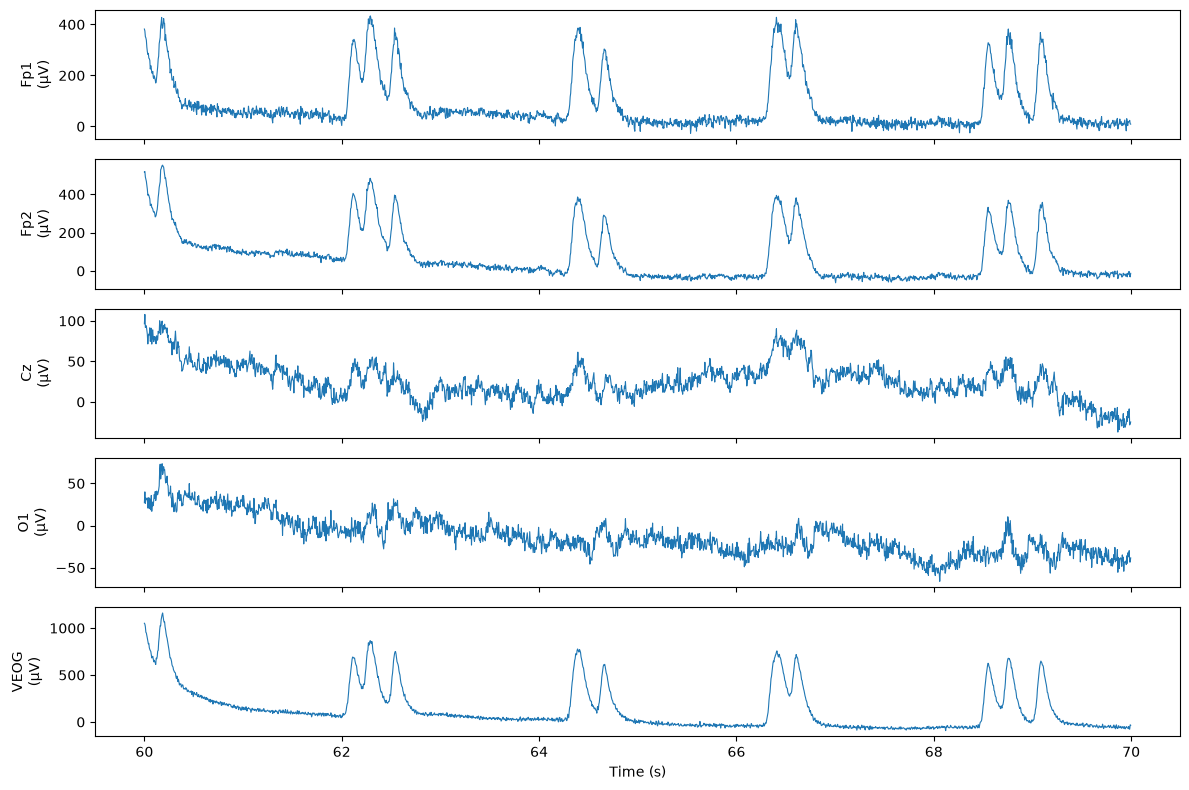

In [12]:
start_sec = 60  # skip the first minute (setup noise is common at the start)
window_sec = 10

start = int(start_sec * cnt.fs)
stop = start + int(window_sec * cnt.fs)
time = np.arange(start, stop) / cnt.fs

chans_to_plot = ["Fp1", "Fp2", "Cz", "O1", "VEOG"]

fig, axes = plt.subplots(len(chans_to_plot), 1, figsize=(12, 8), sharex=True)

for ax, ch in zip(axes, chans_to_plot):
    idx = channel_names.index(ch)
    ax.plot(time, cnt.x[start:stop, idx], linewidth=0.8)
    ax.set_ylabel(f"{ch}\n(µV)")

axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

In [10]:
mrk_file = DATA_DIR / "EEG_01-26_MATLAB" / "VP001-EEG" / "mrk_nback.mat"
mrk_mat = scipy.io.loadmat(mrk_file, squeeze_me=True, struct_as_record=False)

mrk_keys = [k for k in mrk_mat.keys() if not k.startswith("__")]
print(mrk_keys)

mrk = mrk_mat[mrk_keys[0]]
print(type(mrk))

['mrk_nback']
<class 'scipy.io.matlab._mio5_params.mat_struct'>


In [11]:
for name in mrk._fieldnames:
    value = getattr(mrk, name)
    shape = getattr(value, "shape", None)
    print(f"{name:12s} type={type(value).__name__:12s} shape={shape}")

time         type=ndarray      shape=(567,)
y            type=ndarray      shape=(8, 567)
className    type=ndarray      shape=(8,)
event        type=mat_struct   shape=None


In [13]:
print("Class names:")
print(mrk.className)

counts = mrk.y.sum(axis=1)
print("\nEvents per class:")
for name, c in zip(mrk.className, counts):
    print(f"  {name:30s} {int(c)}")

print("\nEach event belongs to exactly one class?", np.all(mrk.y.sum(axis=0) == 1))

print("\nFirst 10 times:", mrk.time[:10])
print("Last time:", mrk.time[-1])
print("Recording length in ms:", n_samples / cnt.fs * 1000)

print("\nFields inside event:", mrk.event._fieldnames)

Class names:
['0-back target' '2-back target' '2-back non-target' '3-back target'
 '3-back non-target' '0-back session' '2-back session' '3-back session']

Events per class:
  0-back target                  180
  2-back target                  54
  2-back non-target              126
  3-back target                  54
  3-back non-target              126
  0-back session                 9
  2-back session                 9
  3-back session                 9

Each event belongs to exactly one class? True

First 10 times: [30000 30128 32358 34572 36771 38997 41201 43416 45667 47848]
Last time: 1944646
Recording length in ms: 1974650.0

Fields inside event: ['desc']


In [14]:
import pandas as pd

class_idx = mrk.y.argmax(axis=0)

events = pd.DataFrame({
    "time_s": mrk.time / 1000,
    "label":  mrk.className[class_idx],
    "desc":   mrk.event.desc,
})

events.head(25)

,time_s,label,desc
0,30.000,3-back session,144
1,30.128,3-back non-target,96
2,32.358,3-back non-target,96
3,34.572,3-back non-target,96
4,36.771,3-back target,80
5,38.997,3-back non-target,96
6,41.201,3-back non-target,96
7,43.416,3-back target,80
8,45.667,3-back non-target,96
9,47.848,3-back non-target,96


In [15]:
blocks = events[events["label"].str.endswith("session")].reset_index(drop=True)
blocks["gap_s"] = blocks["time_s"].diff()
blocks

,time_s,label,desc,gap_s
0,30.000,3-back session,144,NaN
1,99.581,2-back session,128,69.581
2,169.008,0-back session,112,69.427
3,238.546,2-back session,128,69.538
4,307.987,0-back session,112,69.441
5,377.546,3-back session,144,69.559
6,447.176,0-back session,112,69.630
7,516.680,3-back session,144,69.504
8,585.925,2-back session,128,69.245
9,688.070,2-back session,128,102.145


In [16]:
nirs_dir = DATA_DIR / "NIRS_01-26_MATLAB" / "VP001-NIRS"
print(nirs_dir.exists())

for f in sorted(nirs_dir.iterdir()):
    print(f.name)

True
cnt_dsr.mat
cnt_nback.mat
cnt_wg.mat
mnt_dsr.mat
mnt_nback.mat
mnt_wg.mat
mrk_dsr.mat
mrk_nback.mat
mrk_wg.mat


In [19]:
nirs_file = nirs_dir / "cnt_nback.mat"          # which file? look at Cell 15's output
nirs_mat = scipy.io.loadmat(nirs_file, squeeze_me=True, struct_as_record=False)

nirs_keys = [k for k in nirs_mat.keys() if not k.startswith("__")]
print(nirs_keys)

nirs_cnt = nirs_mat[nirs_keys[0]]
print(type(nirs_cnt))
print(nirs_cnt._fieldnames)

['cnt_nback']
<class 'scipy.io.matlab._mio5_params.mat_struct'>
['deoxy', 'oxy']


In [25]:
oxy = nirs_cnt.oxy
deoxy = nirs_cnt.deoxy

print("oxy fields:", oxy._fieldnames)
print("deoxy fields:", deoxy._fieldnames)

print("Sampling rate:", oxy.fs, "Hz")
print("Unit:", oxy.yUnit)
print("Number of channels:", len(oxy.clab))
print("Channel names:", oxy.clab)
print("oxy x shape:", oxy.x.shape)
print("deoxy x shape:", deoxy.x.shape)

oxy fields: ['fs', 'nSources', 'nDetectors', 'multiplexing', 'clab', 'x', 'wavelengths', 'signal', 'yUnit', 'title', 'file', 'xInfo']
deoxy fields: ['fs', 'nSources', 'nDetectors', 'multiplexing', 'clab', 'x', 'wavelengths', 'signal', 'yUnit', 'title', 'file', 'xInfo']
Sampling rate: 10 Hz
Unit: mmol/L
Number of channels: 36
Channel names: ['AF7' 'AFF5' 'AFp7' 'AF5h' 'AFp3' 'AFF3h' 'AF1' 'AFFz' 'AFpz' 'AF2'
 'AFp4' 'FCC3' 'C3h' 'C5h' 'CCP3' 'CPP3' 'P3h' 'P5h' 'PPO3' 'AFF4h' 'AF6h'
 'AFF6' 'AFp8' 'AF8' 'FCC4' 'C6h' 'C4h' 'CCP4' 'CPP4' 'P6h' 'P4h' 'PPO4'
 'PPOz' 'PO1' 'PO2' 'POOz']
oxy x shape: (21178, 36)
deoxy x shape: (21178, 36)


In [28]:
print("Sources:", oxy.nSources, "| Detectors:", oxy.nDetectors)
print("Wavelengths:", oxy.wavelengths)
print("Signal:", oxy.signal)
print("Multiplexing:", oxy.multiplexing)
print("xInfo type:", type(oxy.xInfo))

nirs_duration = oxy.x.shape[0] / oxy.fs
print("\nNIRS duration:", nirs_duration, "s")
print("EEG duration:", duration_sec, "s")
print("Difference:", nirs_duration - duration_sec, "s")

Sources: 16 | Detectors: 16
Wavelengths: [760 850]
Signal: NIRS (oxy, deoxy)
Multiplexing: single
xInfo type: <class 'str'>

NIRS duration: 2117.8 s
EEG duration: 1974.65 s
Difference: 143.1500000000001 s


NIRS class names: ['0-back session' '2-back session' '3-back session']
Same block order? True
First 3 NIRS labels: ['3-back session' '2-back session' '0-back session']
First 3 EEG labels:  ['3-back session' '2-back session' '0-back session']

Shift (NIRS − EEG), first 5: [16.56  16.579 16.56  16.622 16.589]
Shift min/max: 16.560000000000002 110.11400000000003


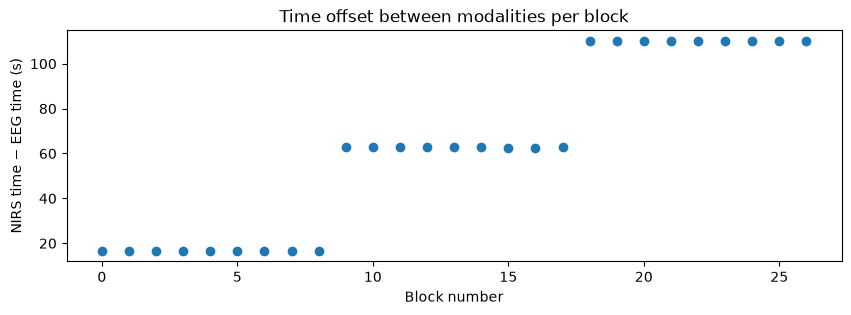

In [30]:
print("NIRS class names:", nirs_mrk.className)

nirs_labels = nirs_mrk.className[nirs_mrk.y.argmax(axis=0)]
eeg_block_t = blocks["time_s"].to_numpy()
eeg_block_labels = blocks["label"].to_numpy()

print("Same block order?", np.array_equal(nirs_labels, eeg_block_labels))
print("First 3 NIRS labels:", nirs_labels[:3])
print("First 3 EEG labels: ", eeg_block_labels[:3])

shift = nirs_t - eeg_block_t
print("\nShift (NIRS − EEG), first 5:", shift[:5])
print("Shift min/max:", shift.min(), shift.max())

plt.figure(figsize=(10, 3))
plt.plot(shift, marker="o", linestyle="")
plt.xlabel("Block number")
plt.ylabel("NIRS time − EEG time (s)")
plt.title("Time offset between modalities per block")
plt.show()

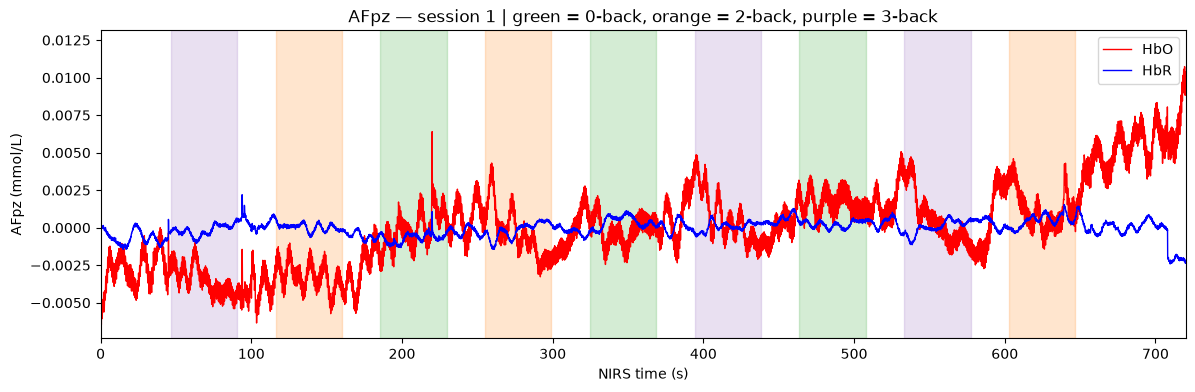

In [31]:
nirs_ch_names = list(oxy.clab)
ch = "AFpz"                      # midline prefrontal channel
idx = nirs_ch_names.index(ch)

nirs_time = np.arange(oxy.x.shape[0]) / oxy.fs

block_colors = {
    "0-back session": "tab:green",
    "2-back session": "tab:orange",
    "3-back session": "tab:purple",
}
task_len = 44 # seconds of task per block

fig, ax = plt.subplots(figsize=(14, 4))

for t, lab in zip(nirs_t, nirs_labels):
    ax.axvspan(t, t + task_len, color=block_colors[lab], alpha=0.2)

ax.plot(nirs_time, oxy.x[:, idx], color="red", linewidth=1, label="HbO")
ax.plot(nirs_time, deoxy.x[:, idx], color="blue", linewidth=1, label="HbR")

ax.set_xlim(0, 720)              # session 1 only
ax.set_xlabel("NIRS time (s)")
ax.set_ylabel(f"{ch} ({oxy.yUnit})")
ax.set_title(f"{ch} — session 1 | green = 0-back, orange = 2-back, purple = 3-back")
ax.legend(loc="upper right")
plt.show()

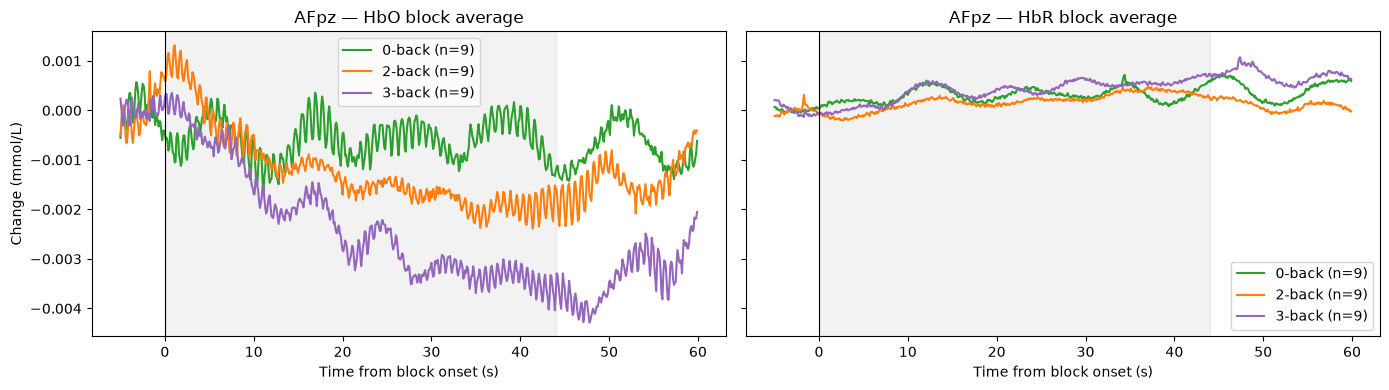

In [32]:
pre_sec = 5        # seconds before block onset (baseline)
post_sec = 60      # seconds after block onset
n_pre = int(pre_sec * oxy.fs)
n_post = int(post_sec * oxy.fs)
epoch_time = np.arange(-n_pre, n_post) / oxy.fs

signals = [("HbO", oxy.x), ("HbR", deoxy.x)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

for ax, (sig_name, data) in zip(axes, signals):
    for lab, color in block_colors.items():
        segments = []
        for t, block_lab in zip(nirs_t, nirs_labels):
            if block_lab != lab:
                continue
            onset = int(round(t * oxy.fs))
            seg = data[onset - n_pre : onset + n_post, idx]
            seg = seg - seg[:n_pre].mean()
            segments.append(seg)

        segments = np.array(segments)
        ax.plot(epoch_time, segments.mean(axis=0), color=color,
                label=f"{lab.replace(' session', '')} (n={len(segments)})")

    ax.axvspan(0, task_len, color="gray", alpha=0.1)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{ch} — {sig_name} block average")
    ax.set_xlabel("Time from block onset (s)")
    ax.legend()

axes[0].set_ylabel(f"Change ({oxy.yUnit})")
plt.tight_layout()
plt.show()

In [33]:
def get_block_epochs(data, onsets_s, labels, fs, ch_idx, level, pre_sec=5, post_sec=60):
    """Cut out all blocks of one workload level from one channel.

    Returns: epochs (n_blocks × n_samples) and the matching time axis in seconds.
    """
    n_pre = int(pre_sec * fs)
    n_post = int(post_sec * fs)
    time = np.arange(-n_pre, n_post) / fs

    segments = []
    for t, lab in zip(onsets_s, labels):
        if lab != level:
            continue
        onset = int(round(t * fs))
        seg = data[onset - n_pre : onset + n_post, ch_idx]
        seg = seg - seg[:n_pre].mean()
        segments.append(seg)

    return np.array(segments), time

In [34]:
def plot_block_averages(ax, data, onsets_s, labels, fs, ch_idx, title):
    for lab, color in block_colors.items():
        epochs, time = get_block_epochs(data, onsets_s, labels, fs, ch_idx, lab)

        mean = epochs.mean(axis=0)
        sem = epochs.std(axis=0, ddof=1) / np.sqrt(len(epochs))

        ax.plot(time, mean, color=color, label=lab.replace(" session", ""))
        ax.fill_between(time, mean - sem, mean + sem, color=color, alpha=0.2)

    ax.axvspan(0, task_len, color="gray", alpha=0.1)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Time from block onset (s)")
    ax.legend()

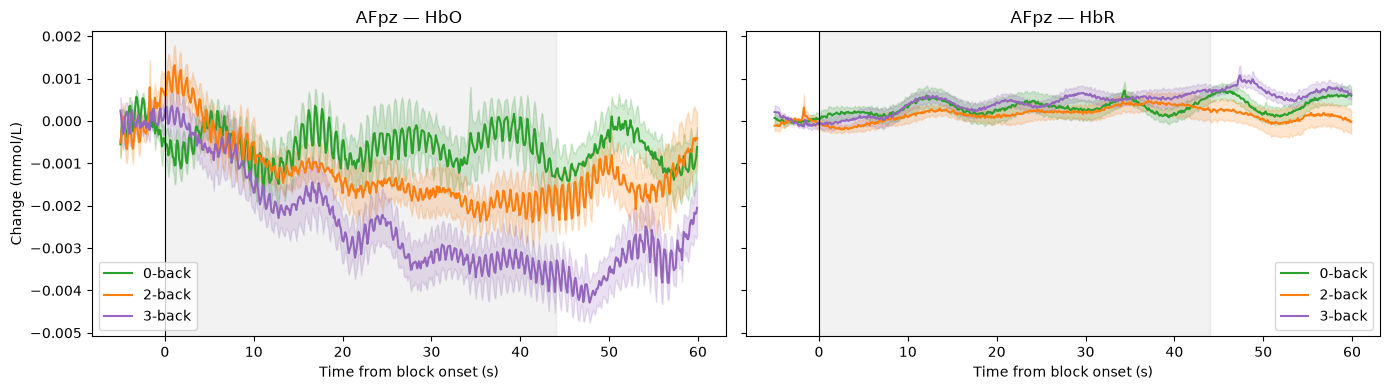

In [35]:
ch = "AFpz"
idx = nirs_ch_names.index(ch)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
plot_block_averages(axes[0], oxy.x,   nirs_t, nirs_labels, oxy.fs, idx, f"{ch} — HbO")
plot_block_averages(axes[1], deoxy.x, nirs_t, nirs_labels, oxy.fs, idx, f"{ch} — HbR")
axes[0].set_ylabel(f"Change ({oxy.yUnit})")
plt.tight_layout()
plt.show()